raw -0.039 tuned 0.188 subj 0.387 agree raw 0.34 tuned 0.75 -> Moderately bullish
{'Positive': 10, 'Neutral': 11, 'Negative': 11} {'Positive': 20, 'Neutral': 5, 'Negative': 7}
{'Global cues': -0.186, 'Oil / geopolitics': -0.067, 'Corporate risk': 0.0, 'Risk event': 0.0, 'Technical': 0.125, 'Breadth': 0.136, 'Earnings': 0.2, 'Policy': 0.238, 'Flows': 0.432, 'Index move': 0.596}
done


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

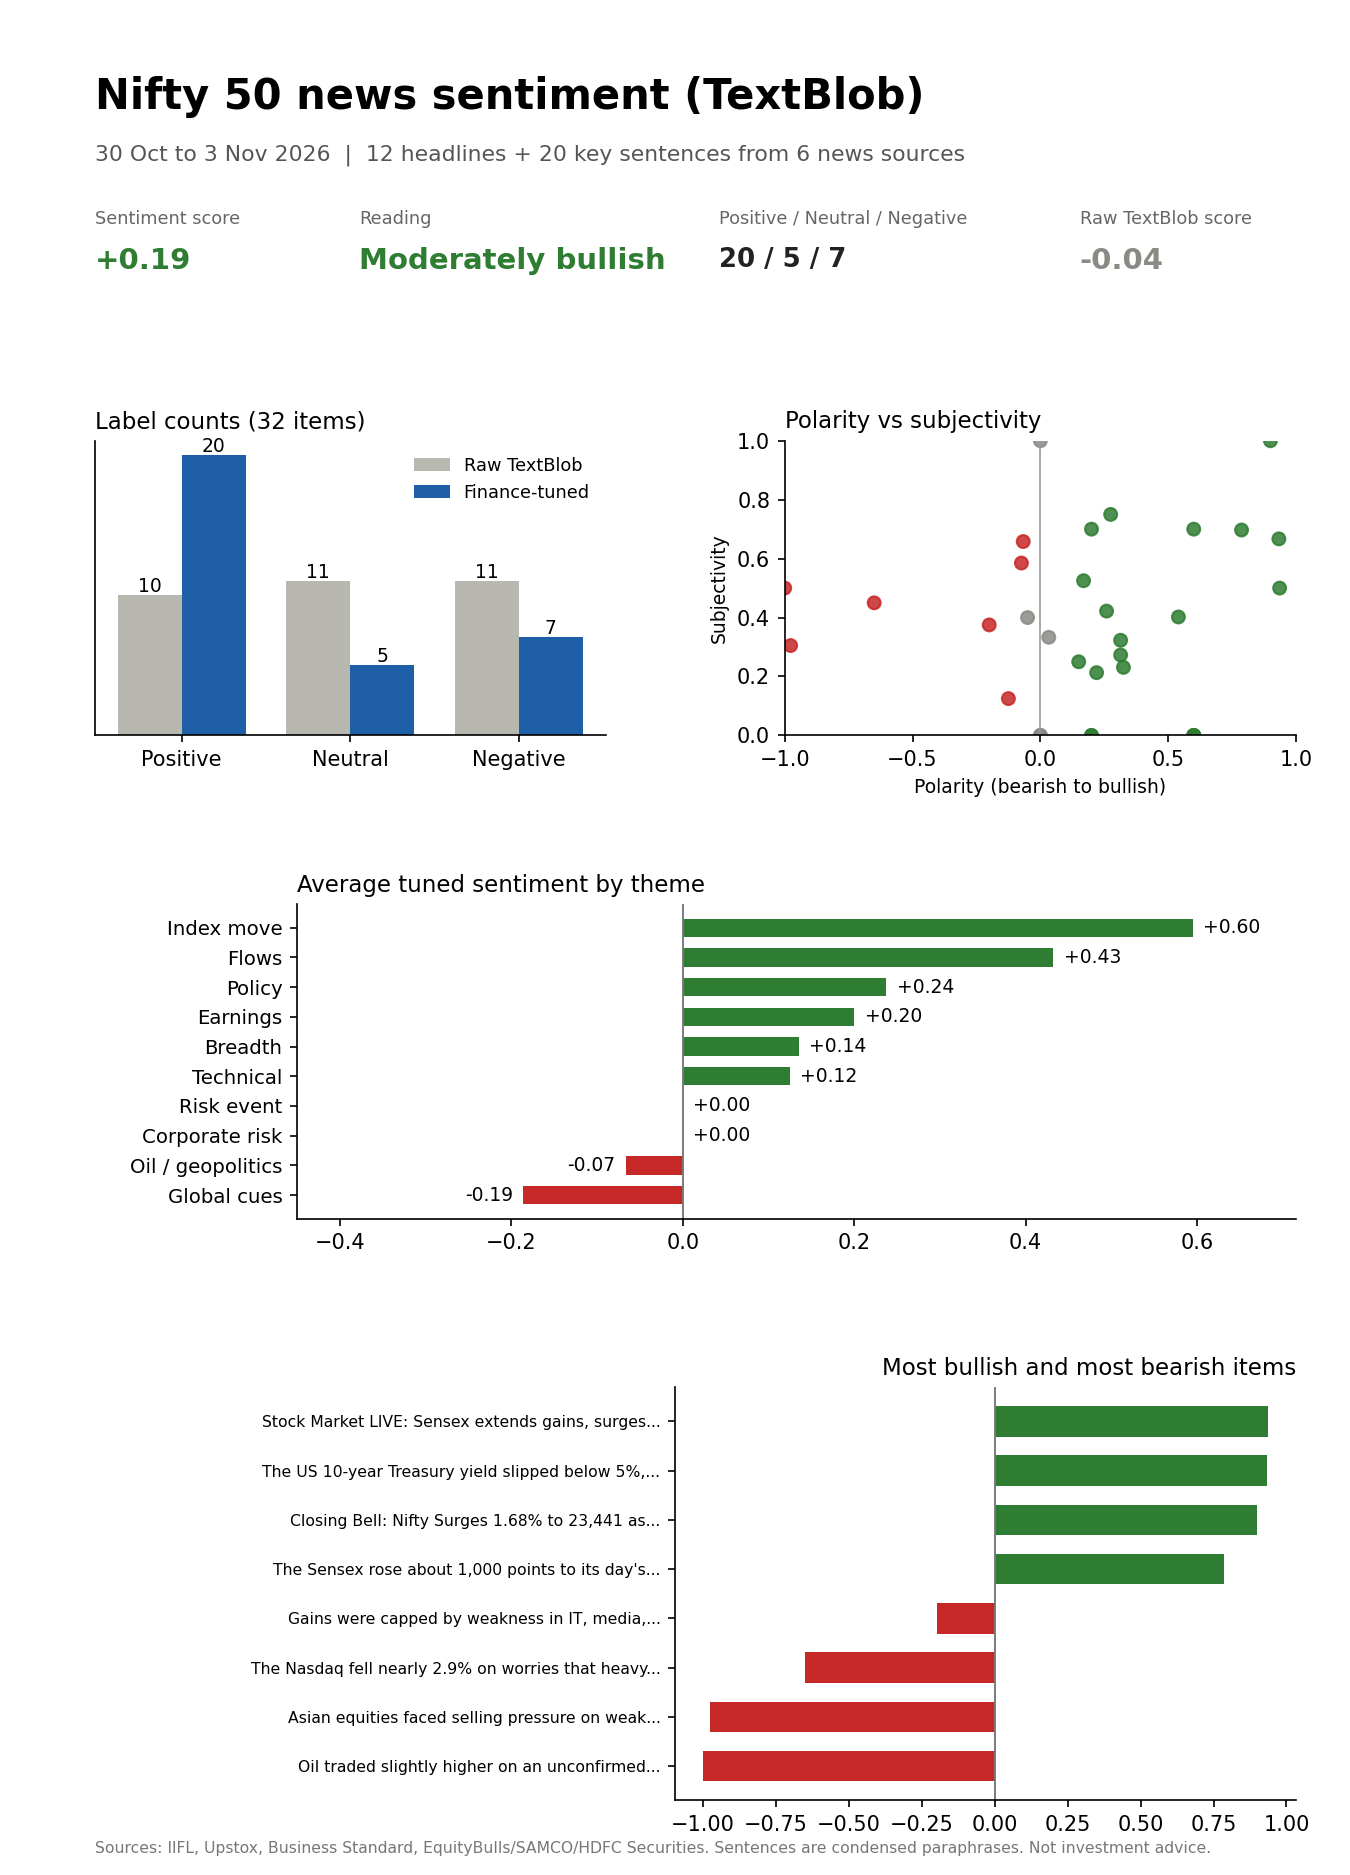

In [1]:

"""
Nifty 50 news sentiment analysis with TextBlob  ->  PDF report + PNG dashboard
Run in Google Colab: paste into one cell and press Run. Files are saved in /content and downloaded automatically.
Headlines are published titles; sentences are condensed paraphrases of the reporting (30 Oct - 3 Nov 2026).
Edit the list D below to analyse your own headlines: (type, theme, source, date, text, your_view[+1/0/-1]).
"""
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "textblob", "reportlab", "matplotlib", "pandas"], check=False)

import re, textwrap
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from textblob import TextBlob

OUT = "/content" if os.path.isdir("/content") else "./output"
os.makedirs(OUT, exist_ok=True)

D = [
 ("Headline","Index move","IIFL","2 Nov","Closing Bell: Nifty Surges 1.68% to 23,441 as Reliance Rallies 11.6% on Record Profit, Crude Cools Below $110",1),
 ("Headline","Index move","IIFL","30 Oct","Closing Bell: Nifty Reclaims 23,000 as IT and Pharma Lead, Trent Surges 5% on 25% Q2 Profit Growth, IndiGo Narrows Loss",1),
 ("Headline","Index move","Upstox","3 Nov","SENSEX gains 600 points; NIFTY50 opens at 23,582 level; IndiGo, Shriram Finance, Asian Paints lead pack of gainers",1),
 ("Headline","Index move","Business Standard","3 Nov","Stock Market LIVE: Sensex extends gains, surges 1,000 pts, Nifty reclaims 23,700; FMCG, realty shine",1),
 ("Headline","Index move","EquityBulls","2 Nov","Nifty Surges Past 23,400 as RIL Powers the Rally",1),
 ("Headline","Technical","EquityBulls / SAMCO","30 Oct","Nifty Ends October on a Positive Note, Holds Above 23,000",1),
 ("Headline","Breadth","EquityBulls","30 Oct","Nifty Rises for Second Straight Session to Two-Week High; Midcaps, Smallcaps Fall Sharply",0),
 ("Headline","Oil / geopolitics","IIFL","2 Nov","Crude Oil Slides Nearly 4% as US-Iran Talks Raise Hopes of Peace; Can Supply Risks Keep Prices Elevated?",1),
 ("Headline","Policy","IIFL","2 Nov","SEBI recommends removing 12.5% LTCG tax for foreign investors in pre-budget proposal",1),
 ("Headline","Earnings","Upstox","3 Nov","Bajaj Finserv Q2 profit rises 23% to Rs 2,758 crore, revenue climbs 17%",1),
 ("Headline","Earnings","Upstox","3 Nov","Trident shares rally 13% as Q2 profit soars 93% YoY; approves Rs 4,650 crore capacity expansion plan",1),
 ("Headline","Corporate risk","Upstox","3 Nov","HPCL rises 4%; fire incident at refinery in focus; what investors should know",-1),

 ("Sentence","Earnings","IIFL","2 Nov","Reliance reported its highest-ever quarterly profit, up 33.8% year on year, and its record EBITDA lifted the index heavyweight sharply.",1),
 ("Sentence","Earnings","IIFL","2 Nov","Brokerages stayed positive on Reliance but flagged weak retail performance and expect refining margins to ease in the December quarter.",0),
 ("Sentence","Oil / geopolitics","IIFL","2 Nov","Brent crude fell about 3% to nearly $110 after Iranian and Qatari talks aimed at ending the war, easing worries about inflation and the import bill.",1),
 ("Sentence","Global cues","IIFL","2 Nov","The Nasdaq fell nearly 2.9% on worries that heavy AI spending may not pay off, which triggered selling in Indian IT stocks.",-1),
 ("Sentence","Global cues","IIFL","2 Nov","Analysts say India is a beneficiary as money rotates out of expensive tech and the weakening AI trade helps domestic markets.",1),
 ("Sentence","Flows","IIFL","2 Nov","Foreign investors bought about Rs 13,213 crore of Indian equities in the last week of October and added more on Friday.",1),
 ("Sentence","Global cues","IIFL","2 Nov","The US 10-year Treasury yield slipped below 5%, making emerging markets such as India more attractive.",1),
 ("Sentence","Policy","IIFL","2 Nov","Hopes of a cut or abolition of the long-term capital gains tax in the Budget lifted sentiment, though there is no official confirmation.",1),
 ("Sentence","Breadth","IIFL","2 Nov","Gains were capped by weakness in IT, media, pharma and private banking stocks.",-1),
 ("Sentence","Technical","EquityBulls","2 Nov","Nifty closed at the day's high, forming a bullish candle, and left its opening gap unfilled.",1),
 ("Sentence","Technical","SAMCO","30 Oct","Put writing across the 22,550 to 22,950 strikes provides a strong base, while call open interest near 23,450 to 23,500 may act as a ceiling.",0),
 ("Sentence","Technical","SAMCO","30 Oct","A sustained move above the 38.2% retracement level near 23,170 is required to build further confidence in the recovery.",0),
 ("Sentence","Breadth","EquityBulls","30 Oct","Midcaps and smallcaps fell sharply even as the Nifty rose for a second straight session.",-1),
 ("Sentence","Oil / geopolitics","Upstox","3 Nov","Oil traded slightly higher on an unconfirmed report that the US attacked Qeshm Island in Iran, raising fears of further escalation.",-1),
 ("Sentence","Global cues","Upstox","3 Nov","Asian equities faced selling pressure on weak Wall Street cues and rising fears over the winding down of the AI trade.",-1),
 ("Sentence","Flows","Upstox","3 Nov","Foreign institutional investors bought around Rs 3,115 crore of equities on Monday, supporting the strong open.",1),
 ("Sentence","Breadth","Upstox","3 Nov","Thirty-four of the 50 Nifty stocks were trading in positive territory in the morning, led by IndiGo, Shriram Finance and Asian Paints.",1),
 ("Sentence","Risk event","Upstox","3 Nov","Investors will watch crude oil, West Asia developments and the US midterm elections scheduled this week.",-1),
 ("Sentence","Index move","Business Standard","3 Nov","The Sensex rose about 1,000 points to its day's high as FMCG, chemical and IT shares advanced on the unwinding of the AI trade.",1),
 ("Sentence","Earnings","Business Standard","3 Nov","SBI, NSE, Bajaj Finserv, Lupin and MCX are among the companies releasing second-quarter results today.",0),
]

rows = []
for typ, theme, src, date, text, impact in D:
    s = TextBlob(text).sentiment
    pol = round(s.polarity, 3)
    label = "Positive" if pol > 0.05 else "Negative" if pol < -0.05 else "Neutral"
    rows.append(dict(type=typ, theme=theme, source=src, date=date, text=text,
                     polarity=pol, subjectivity=round(s.subjectivity, 3),
                     textblob_label=label, impact=impact))
df = pd.DataFrame(rows)
df = pd.DataFrame(rows)
UP = {"surge","surges","surged","rally","rallies","rallied","gain","gains","gained","rises","rise","rose","reclaim",
      "reclaims","record","highest","jump","soars","bullish","bought","buying","beneficiary","attractive","lifted",
      "advanced","approves","approval","growth","support","positive","extends","hopes","strong"}
DOWN = {"fell","falls","slide","slides","slipped","weak","weakness","selling","capped","escalation","fears","fear",
        "attacked","attack","fire","unconfirmed","ceiling","worries","decline","declined","pressure"}
OIL = r"(crude|brent|oil|yield)"
OIL_FALL = re.compile(OIL + r"[^,.;]*?\b(fell|slides?|slipped|cools?|declin\w+|eas\w+)\b", re.I)
OIL_RISE = re.compile(OIL + r"[^,.;]*?\b(rises?|rose|higher|surg\w+)\b", re.I)

def tuned(text):
    bonus = 0
    t = text
    for rx, val in ((OIL_FALL, 1), (OIL_RISE, -1)):
        hits = rx.findall(t)
        bonus += val * len(hits)
        t = rx.sub(" ", t)
    t = re.sub(r"\bcrude\b", "oil", t, flags=re.I)
    base = TextBlob(t).sentiment.polarity
    words = re.findall(r"[a-z\-]+", t.lower())
    net = sum(w in UP for w in words) - sum(w in DOWN for w in words)
    return float(np.clip(base + 0.2 * net + 0.3 * bonus, -1, 1))

def lab(p):
    return "Positive" if p > 0.05 else "Negative" if p < -0.05 else "Neutral"

df["tuned"] = df.text.map(tuned).round(3)
df["tuned_label"] = df.tuned.map(lab)
sign = df.impact.map(lambda x: "Positive" if x > 0 else "Negative" if x < 0 else "Neutral")
agree_raw = (sign == df.textblob_label).mean()
agree_tuned = (sign == df.tuned_label).mean()
df.to_csv(f"{OUT}/nifty_sentiment_scores.csv", index=False)

mean_raw, mean_tuned = df.polarity.mean(), df.tuned.mean()
subj = df.subjectivity.mean()
cnt_raw = df.textblob_label.value_counts().reindex(["Positive", "Neutral", "Negative"]).fillna(0).astype(int)
cnt_tuned = df.tuned_label.value_counts().reindex(["Positive", "Neutral", "Negative"]).fillna(0).astype(int)
theme = df.groupby("theme").tuned.mean().sort_values()
verdict = "Moderately bullish" if mean_tuned > 0.1 else "Mildly bullish" if mean_tuned > 0.03 else "Neutral" if mean_tuned > -0.03 else "Bearish"
print(f"raw {mean_raw:.3f} tuned {mean_tuned:.3f} subj {subj:.3f} agree raw {agree_raw:.2f} tuned {agree_tuned:.2f} -> {verdict}")
print(cnt_raw.to_dict(), cnt_tuned.to_dict()); print(theme.round(3).to_dict())

GREEN, RED, GRAY, BLUE = "#2E7D32", "#C62828", "#8A8A85", "#1F5FA8"
colr = lambda v: GREEN if v > 0.05 else RED if v < -0.05 else GRAY

# ---------------- image ----------------
fig = plt.figure(figsize=(9, 12.5), dpi=150, facecolor="white")
gs = fig.add_gridspec(4, 2, height_ratios=[1.05, 1.5, 1.6, 2.1], hspace=0.55, wspace=0.35,
                      left=0.07, right=0.96, top=0.965, bottom=0.04)
ax = fig.add_subplot(gs[0, :]); ax.axis("off")
ax.text(0, 0.95, "Nifty 50 news sentiment (TextBlob)", fontsize=20, fontweight="bold", va="top")
ax.text(0, 0.62, "30 Oct to 3 Nov 2026  |  12 headlines + 20 key sentences from 6 news sources", fontsize=10.5, color="#555", va="top")
kp = [("Sentiment score", f"{mean_tuned:+.2f}", colr(mean_tuned)), ("Reading", verdict, colr(mean_tuned)),
      ("Positive / Neutral / Negative", f"{cnt_tuned['Positive']} / {cnt_tuned['Neutral']} / {cnt_tuned['Negative']}", "#222"),
      ("Raw TextBlob score", f"{mean_raw:+.2f}", GRAY)]
for i, (k, v, c) in enumerate(kp):
    x = [0, .22, .52, .82][i]
    ax.text(x, 0.30, k, fontsize=8.5, color="#666", va="top")
    ax.text(x, 0.12, v, fontsize=14 if i != 2 else 12.5, fontweight="bold", color=c, va="top")

a1 = fig.add_subplot(gs[1, 0])
x = np.arange(3); w = 0.38
a1.bar(x - w/2, cnt_raw.values, w, color="#B9B8B0", label="Raw TextBlob")
a1.bar(x + w/2, cnt_tuned.values, w, color=BLUE, label="Finance-tuned")
for i in range(3):
    a1.text(i - w/2, cnt_raw.values[i] + .2, cnt_raw.values[i], ha="center", fontsize=9)
    a1.text(i + w/2, cnt_tuned.values[i] + .2, cnt_tuned.values[i], ha="center", fontsize=9)
a1.set_xticks(x, ["Positive", "Neutral", "Negative"]); a1.set_title("Label counts (32 items)", fontsize=11, loc="left")
a1.legend(frameon=False, fontsize=8.5); a1.spines[["top", "right"]].set_visible(False); a1.set_yticks([])

a2 = fig.add_subplot(gs[1, 1])
a2.scatter(df.tuned, df.subjectivity, c=[colr(v) for v in df.tuned], s=38, alpha=.85)
a2.set_xticks([-1, -.5, 0, .5, 1]); a2.axvline(0, color="#999", lw=.8); a2.set_xlim(-1, 1); a2.set_ylim(0, 1)
a2.set_xlabel("Polarity (bearish to bullish)", fontsize=9); a2.set_ylabel("Subjectivity", fontsize=9)
a2.set_title("Polarity vs subjectivity", fontsize=11, loc="left"); a2.spines[["top", "right"]].set_visible(False)

p3 = gs[2, :].get_position(fig); a3 = fig.add_axes([0.22, p3.y0, 0.74, p3.height])
a3.barh(theme.index, theme.values, color=[colr(v) for v in theme.values], height=.62)
a3.axvline(0, color="#777", lw=.9)
for i, v in enumerate(theme.values):
    a3.text(v + (0.012 if v >= 0 else -0.012), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
a3.set_title("Average tuned sentiment by theme", fontsize=11, loc="left")
a3.set_xlim(min(-0.45, theme.min() - .1), max(0.65, theme.max() + .12)); a3.spines[["top", "right"]].set_visible(False); a3.tick_params(axis="y", labelsize=9.5)

p4 = gs[3, :].get_position(fig); a4 = fig.add_axes([0.50, p4.y0, 0.46, p4.height])
pick = pd.concat([df.nlargest(4, "tuned"), df.nsmallest(4, "tuned")]).sort_values("tuned")
labels = [textwrap.shorten(t, 52, placeholder="...") for t in pick.text]
a4.barh(labels, pick.tuned, color=[colr(v) for v in pick.tuned], height=.62)
a4.axvline(0, color="#777", lw=.9)
a4.set_title("Most bullish and most bearish items", fontsize=11, loc="right"); a4.tick_params(axis="y", labelsize=7.5)
a4.spines[["top", "right"]].set_visible(False)
fig.text(0.07, 0.012, "Sources: IIFL, Upstox, Business Standard, EquityBulls/SAMCO/HDFC Securities. Sentences are condensed paraphrases. Not investment advice.", fontsize=7.5, color="#777")
fig.savefig(f"{OUT}/nifty_sentiment_dashboard.png", dpi=150)
plt.close(fig)

# ---------------- PDF ----------------
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import mm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak

ss = getSampleStyleSheet()
H1 = ParagraphStyle("H1", parent=ss["Title"], fontSize=19, alignment=0, spaceAfter=2)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], fontSize=12.5, spaceBefore=8, spaceAfter=4)
B = ParagraphStyle("B", parent=ss["Normal"], fontSize=9.3, leading=13)
S = ParagraphStyle("S", parent=ss["Normal"], fontSize=7.6, leading=9.4)
BL = ParagraphStyle("BL", parent=B, leftIndent=10, bulletIndent=0, spaceAfter=2)

def bl(t): return Paragraph(t, BL, bulletText="\u2022")

doc = SimpleDocTemplate(f"{OUT}/nifty_news_sentiment_report.pdf", pagesize=A4,
                        leftMargin=15*mm, rightMargin=15*mm, topMargin=14*mm, bottomMargin=14*mm,
                        title="Nifty 50 news sentiment analysis", author="Claude")
st = []
st += [Paragraph("Nifty 50 news sentiment and financial analysis", H1),
       Paragraph("Period: 30 Oct to 3 Nov 2026 (as of about 1 PM IST, 3 Nov) | Method: TextBlob polarity and subjectivity on "
                 "12 headlines and 20 key sentences", S), Spacer(1, 6)]
kpi = Table([[f"{mean_tuned:+.2f}", verdict, f"{cnt_tuned['Positive']} / {cnt_tuned['Neutral']} / {cnt_tuned['Negative']}", f"{mean_raw:+.2f}"],
             ["Tuned sentiment score", "Reading", "Positive / Neutral / Negative", "Raw TextBlob score"]],
            colWidths=[36*mm, 52*mm, 50*mm, 36*mm])
kpi.setStyle(TableStyle([("FONTSIZE", (0, 0), (-1, 0), 15), ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
                         ("TEXTCOLOR", (0, 0), (1, 0), colors.HexColor(colr(mean_tuned))), ("TEXTCOLOR", (3, 0), (3, 0), colors.HexColor(GRAY)),
                         ("FONTSIZE", (0, 1), (-1, 1), 7.5), ("TEXTCOLOR", (0, 1), (-1, 1), colors.HexColor("#666666")),
                         ("BACKGROUND", (0, 0), (-1, -1), colors.HexColor("#F5F4EF")), ("TOPPADDING", (0, 0), (-1, -1), 5),
                         ("BOTTOMPADDING", (0, 0), (-1, -1), 5)]))
st += [kpi, Spacer(1, 6)]
st += [Paragraph("Summary", H2),
       Paragraph(f"News flow around the Nifty rally is net positive. The finance-tuned score is {mean_tuned:+.2f} "
                 f"({verdict.lower()}), while untuned TextBlob gives {mean_raw:+.2f}. The gap is a dictionary problem, not a "
                 f"market signal: TextBlob's general dictionary reads \"crude\" as an insult and \"fell\" as bad news even when "
                 f"oil or US yields are falling, which helps India. Average subjectivity is {subj:.2f}, so the coverage mixes "
                 f"reported facts with analyst opinion.", B)]
img_w = 112*mm
st += [Spacer(1, 4), Image(f"{OUT}/nifty_sentiment_dashboard.png", width=img_w, height=img_w * 12.5 / 9)]
st += [PageBreak(), Paragraph("Financial analysis from news sentiment", H2),
       Paragraph("<b>What is driving the positive tone</b>", B),
       bl("<b>Foreign and institutional flows</b> are among the strongest positive themes (after the index moves themselves): heavy FII buying in late October and again on 2 Nov."),
       bl("<b>Earnings:</b> Reliance's record profit powered the 2 Nov rally, and Bajaj Finserv and Trident reported strong Q2 numbers. SBI, NSE and Lupin report today."),
       bl("<b>Easing oil and US yields:</b> Brent cooled toward $110 and the US 10-year yield slipped below 5%, easing inflation and import-bill concerns."),
       bl("<b>Rotation out of AI and tech:</b> selling in US and Asian tech is pushing money toward Indian large caps. Global cues are the most negative theme in the data (tech selloff), yet the news treats the rotation as a net benefit for India."),
       bl("<b>Policy hopes:</b> talk of capital gains tax relief in the Budget, which is not officially confirmed."),
       Spacer(1, 3), Paragraph("<b>What could reverse it</b>", B),
       bl("<b>Geopolitics:</b> an unconfirmed report of a US strike on Iran's Qeshm Island nudged oil back up. Oil/geopolitics is slightly negative in the data."),
       bl("<b>Narrow breadth:</b> on 30 Oct midcaps and smallcaps fell sharply while Nifty rose, and on 2 Nov IT, media, pharma and private banks lagged. A rally led by a few heavyweights is more fragile."),
       bl("<b>Event risk:</b> US midterm elections this week and Q2 earnings from SBI today."),
       bl("<b>Single-stock dependence:</b> Reliance alone, at about 7.3% weight, contributed most of the 2 Nov index gain."),
       Spacer(1, 3), Paragraph("<b>Levels mentioned in the sources</b>", B),
       bl("SAMCO flagged call open interest near 23,450 to 23,500 as a ceiling and the 50-day average near 23,240 as resistance. The index has since traded above both."),
       bl("Yesterday's close (23,440.80) and low (23,207.05) are the nearest reference supports from the candle data; today's high so far is above 23,700."),
       Spacer(1, 3), Paragraph("<b>Conclusion</b>", B),
       Paragraph("Sentiment is moderately bullish and supported by flows, earnings and falling oil. The main risk is that it depends on oil staying "
                 "calm and on a few large stocks. A sustained oil spike or a failure to hold yesterday's gap would change the tone.", B),
       Spacer(1, 6), Paragraph("Method notes and limits", H2),
       bl(f"<b>Tuned score</b> = TextBlob polarity after neutralising words it misreads (\"crude\"), plus +0.2 per bullish finance word, -0.2 per bearish word, "
          f"and a context rule that treats falling oil or yields as positive and rising as negative for India."),
       bl(f"Agreement with my own manual bullish/neutral/bearish read of each item: raw TextBlob {agree_raw:.0%}, tuned {agree_tuned:.0%}. My read is a judgment, not ground truth."),
       bl("The tuning words were chosen after seeing these items, so treat the tuned score as indicative. 32 items is a small sample, and the sources lean to market-wrap articles."),
       bl("Sentiment of news is not a price forecast. This is not investment advice."),
       PageBreak(), Paragraph("Appendix: scored items", H2)]
rows = [["#", "Type", "Theme", "Source / date", "Text", "Raw", "Tuned"]]
for i, r in df.iterrows():
    rows.append([i + 1, r.type, Paragraph(r.theme, S), Paragraph(f"{r.source}<br/>{r.date}", S), Paragraph(r.text, S),
                 f"{r.polarity:+.2f}", f"{r.tuned:+.2f}"])
tb = Table(rows, colWidths=[7*mm, 15*mm, 22*mm, 27*mm, 85*mm, 12*mm, 12*mm], repeatRows=1)
sty = [("FONTSIZE", (0, 0), (-1, -1), 7.6), ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
       ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#E9E8E1")), ("VALIGN", (0, 0), (-1, -1), "TOP"),
       ("LINEBELOW", (0, 0), (-1, -1), 0.25, colors.HexColor("#CCCCCC")), ("TOPPADDING", (0, 0), (-1, -1), 2.5),
       ("BOTTOMPADDING", (0, 0), (-1, -1), 2.5)]
for i, v in enumerate(df.tuned, start=1):
    sty.append(("TEXTCOLOR", (6, i), (6, i), colors.HexColor(colr(v))))
tb.setStyle(TableStyle(sty))
st.append(tb)
doc.build(st)
print("done")

try:
    from google.colab import files
    for f in ("nifty_news_sentiment_report.pdf", "nifty_sentiment_dashboard.png", "nifty_sentiment_scores.csv"):
        files.download(f"{OUT}/{f}")
except ImportError:
    print("Files saved in", OUT)
from IPython.display import Image as _Img, display
display(_Img(f"{OUT}/nifty_sentiment_dashboard.png", width=600))